# Exploratory Data Analysis (EDA) — CarDekho Used Car Listings

**Dataset:** `data/final_destination.csv` (`15,229` listings × `15` columns, Indian Rupees `₹`, `1 Lakh = ₹100,000`), with `brand` mapped `1-to-1` by `model` from `data/cardekho_cleaned.csv` (`ISUZU` standardized to `Isuzu`, giving `31` brands).

> **Scope Note:** `selling_price` represents cross-sectional advertised asking prices (not completed transactions). Cohorts with `n < 30` (`68` listings across ages `0` and `16–29`, including the single Age-25 `BMW 320d` `₹10.00L` anomaly) are flagged in age trend plots.

| Acceptance Criterion | Section | Output Figure |
|---|---|---|
| 1. Selling price distribution plots (histogram, KDE, box plot) | Section 2 | `eda_01_selling_price_distribution.png` |
| 2. Price vs Mileage scatter plots & correlation coefficients | Section 3 | `eda_02_price_vs_mileage_scatter.png` |
| 3. Price vs Vehicle Age regression trend lines | Section 4 | `eda_03_price_vs_vehicle_age_regression.png` |
| 4. Model inventory frequency & brand concentration | Section 5 | `eda_04_model_frequency_and_brand_concentration.png` |


## 1. Setup, Data Verification & Central Tendency Summary


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# Resolve Car_Sale_Analysis root reliably
cwd = Path.cwd().resolve()
if (cwd / "data" / "final_destination.csv").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "final_destination.csv").exists():
    PROJECT_ROOT = cwd.parent
elif (cwd / "Car_Sale_Analysis" / "data" / "final_destination.csv").exists():
    PROJECT_ROOT = cwd / "Car_Sale_Analysis"
else:
    raise FileNotFoundError("Could not locate Car_Sale_Analysis project root.")

SCRIPTS_DIR = PROJECT_ROOT / "advanced_analysis" / "scripts"
for p in (str(PROJECT_ROOT), str(SCRIPTS_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from src.config import DATA_DIR, FIGURES_DIR
from common import LAKH, MIN_SAMPLE_SIZE, PALETTE, configure_plot_style, inspect_data_quality, load_dataset

configure_plot_style()
EDA_FIG_DIR = PROJECT_ROOT / "EDA" / "figures"
OUT_FIG_DIR = FIGURES_DIR / "02_exploratory_data_analysis"
EDA_FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_eda_figure(fig: plt.Figure, filename: str) -> Path:
    """Save 300-DPI PNG to EDA/figures and outputs/figures/02_exploratory_data_analysis."""
    eda_path = EDA_FIG_DIR / filename
    fig.savefig(eda_path, dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(OUT_FIG_DIR / filename, dpi=300, bbox_inches="tight", facecolor="white")
    return eda_path


df = load_dataset(DATA_DIR / "final_destination.csv")
dq = inspect_data_quality(df)

# Deterministic 1-to-1 brand mapping from cardekho_cleaned.csv
brand_ref = pd.read_csv(DATA_DIR / "cardekho_cleaned.csv", usecols=["model", "brand"])
brand_ref["brand"] = brand_ref["brand"].replace({"ISUZU": "Isuzu"})
assert (brand_ref.groupby("model")["brand"].nunique() == 1).all()
df["brand"] = df["model"].map(brand_ref.groupby("model")["brand"].first().to_dict())
assert df["brand"].isna().sum() == 0

df["selling_price_lakhs"] = df["selling_price"] / LAKH
df["km_driven_k"] = df["km_driven"] / 1_000.0
df["log_price"] = np.log(df["selling_price"])

print(f"Dataset: {dq['rows']:,} rows x {dq['columns']} base columns (+brand)")
print(f"Missing values: {dq['total_missing']} | Duplicates: {dq['duplicate_rows']}")
print(f"Unique models: {df['model'].nunique()} | Unique standardized brands: {df['brand'].nunique()}")

# Central tendency & spread summary for key numeric features
key_cols = ["selling_price", "vehicle_age", "km_driven", "mileage", "engine", "max_power"]
summary_rows = []
for col in key_cols:
    s = df[col]
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    summary_rows.append({
        "Feature": col,
        "Count": int(s.count()),
        "Mean": float(s.mean()),
        "Median": float(med),
        "Mode": float(s.mode().iloc[0]),
        "Std": float(s.std()),
        "Min": float(s.min()),
        "Q1": float(q1),
        "Q3": float(q3),
        "IQR": float(q3 - q1),
        "Max": float(s.max()),
        "Skewness": float(s.skew()),
        "Kurtosis": float(s.kurtosis()),
    })

display(
    pd.DataFrame(summary_rows).style.format({
        "Count": "{:,}",
        "Mean": "{:,.2f}",
        "Median": "{:,.2f}",
        "Mode": "{:,.2f}",
        "Std": "{:,.2f}",
        "Min": "{:,.2f}",
        "Q1": "{:,.2f}",
        "Q3": "{:,.2f}",
        "IQR": "{:,.2f}",
        "Max": "{:,.2f}",
        "Skewness": "{:+.2f}",
        "Kurtosis": "{:+.2f}",
    })
)


Dataset: 15,229 rows x 15 base columns (+brand)
Missing values: 0 | Duplicates: 0
Unique models: 120 | Unique standardized brands: 31


,Feature,Count,Mean,Median,Mode,Std,Min,Q1,Q3,IQR,Max,Skewness,Kurtosis
0,selling_price,"15,229","774,537.98","556,000.00","450,000.00","894,921.75","40,000.00","385,000.00","825,000.00","440,000.00","39,500,000.00",+10.11,+284.26
1,vehicle_age,"15,229",6.04,6.00,4.00,3.02,0.00,4.00,8.00,4.00,29.00,+0.83,+0.76
2,km_driven,"15,229","54,887.83","50,000.00","50,000.00","37,065.08",100.00,"30,000.00","70,000.00","40,000.00","830,000.00",+2.77,+26.19
3,mileage,"15,229",19.70,19.67,18.90,4.17,4.00,17.00,22.70,5.70,33.54,+0.11,-0.16
4,engine,"15,229","1,485.89","1,248.00","1,197.00",520.25,793.00,"1,197.00","1,582.00",385.00,"6,592.00",+1.67,+4.38
5,max_power,"15,229",100.60,88.50,74.00,42.92,38.40,74.00,117.30,43.30,626.00,+2.49,+11.95


## 2. Vehicle Selling Price Distribution (Histogram, KDE & Box Plot)


Mean: ₹7.75L | Median: ₹5.56L | Mode: ₹4.50L
Q1: ₹3.85L | Q3: ₹8.25L | IQR: ₹4.40L | 1.5xIQR Upper Fence: ₹14.85L
Outliers (> ₹14.85L): 1,370 (9.00%) | Max: ₹395.00L


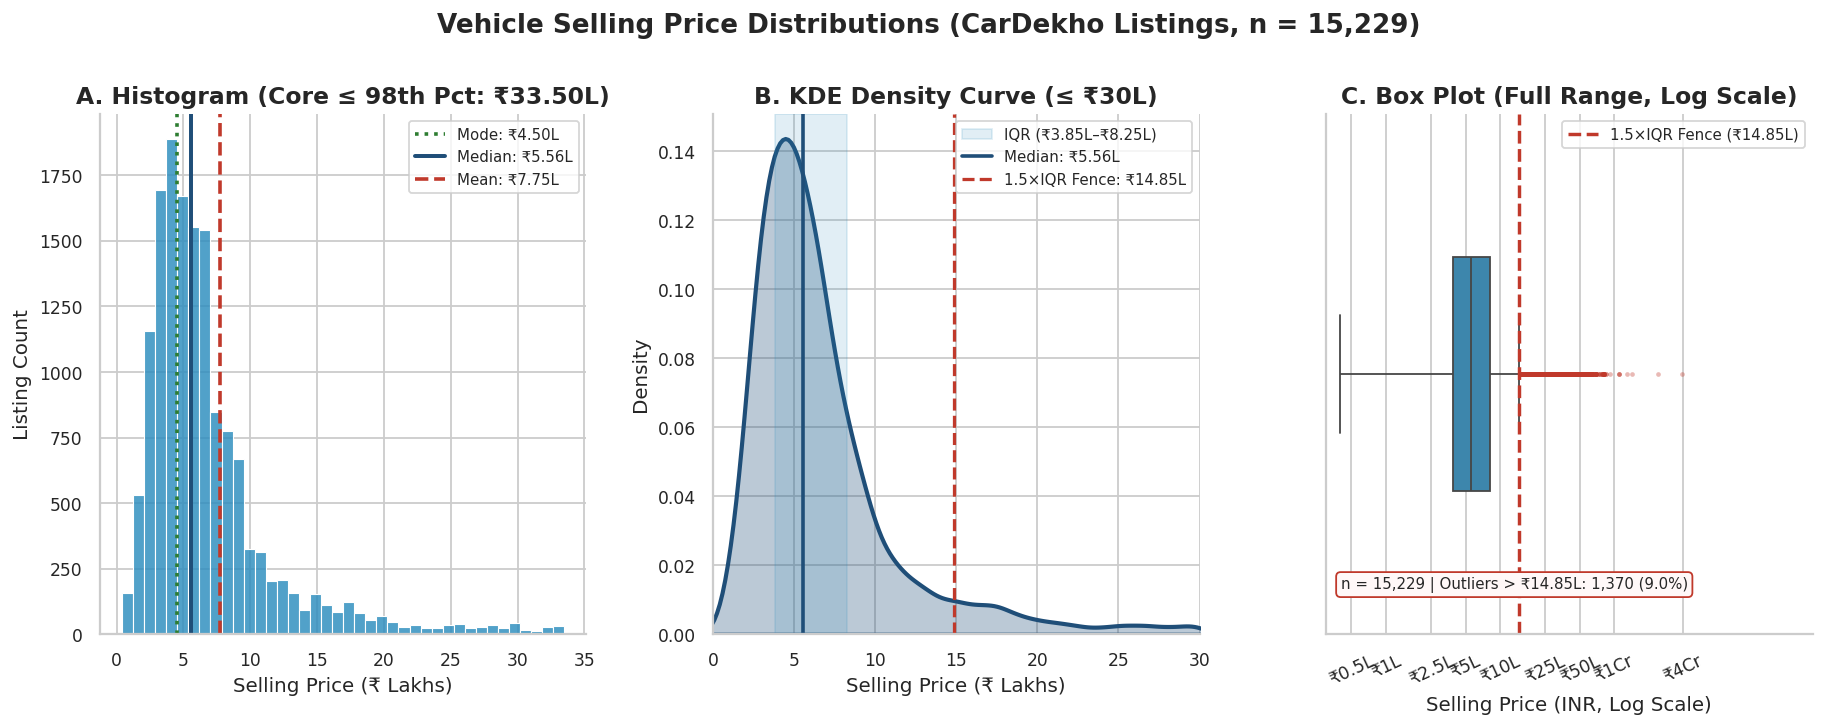

Saved: /home/panha/car_price_prediction/Car_Sale_Analysis/EDA/figures/eda_01_selling_price_distribution.png


In [2]:
p = df["selling_price"]
q1, med, q3 = p.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_out = int((p > upper_fence).sum())
p98 = float(p.quantile(0.98))

print(f"Mean: ₹{p.mean()/LAKH:.2f}L | Median: ₹{med/LAKH:.2f}L | Mode: ₹{p.mode().iloc[0]/LAKH:.2f}L")
print(f"Q1: ₹{q1/LAKH:.2f}L | Q3: ₹{q3/LAKH:.2f}L | IQR: ₹{iqr/LAKH:.2f}L | 1.5xIQR Upper Fence: ₹{upper_fence/LAKH:.2f}L")
print(f"Outliers (> ₹{upper_fence/LAKH:.2f}L): {n_out:,} ({n_out/len(df)*100:.2f}%) | Max: ₹{p.max()/LAKH:.2f}L")

fig, axes = plt.subplots(1, 3, figsize=(17.0, 5.2))
fig.subplots_adjust(wspace=0.26)

# 1. Histogram (Core market <= 98th percentile for readable binning)
ax = axes[0]
core = df[df["selling_price"] <= p98]["selling_price_lakhs"]
sns.histplot(core, bins=40, color=PALETTE["secondary"], edgecolor="white", alpha=0.82, ax=ax)
ax.axvline(p.mode().iloc[0] / LAKH, color=PALETTE["success"], linestyle=":", linewidth=2.0, label=f"Mode: ₹{p.mode().iloc[0]/LAKH:.2f}L")
ax.axvline(med / LAKH, color=PALETTE["primary"], linestyle="-", linewidth=2.2, label=f"Median: ₹{med/LAKH:.2f}L")
ax.axvline(p.mean() / LAKH, color=PALETTE["danger"], linestyle="--", linewidth=2.0, label=f"Mean: ₹{p.mean()/LAKH:.2f}L")
ax.set_title("A. Histogram (Core ≤ 98th Pct: ₹33.50L)")
ax.set_xlabel("Selling Price (₹ Lakhs)")
ax.set_ylabel("Listing Count")
ax.legend(loc="upper right", fontsize=8.3, frameon=True)

# 2. KDE Plot (Core <= ₹30L)
ax = axes[1]
kde_vals = df[df["selling_price"] <= 30 * LAKH]["selling_price_lakhs"]
sns.kdeplot(kde_vals, fill=True, color=PALETTE["primary"], alpha=0.30, linewidth=2.3, ax=ax)
ax.axvspan(q1 / LAKH, q3 / LAKH, color=PALETTE["secondary"], alpha=0.14, label=f"IQR (₹{q1/LAKH:.2f}L–₹{q3/LAKH:.2f}L)")
ax.axvline(med / LAKH, color=PALETTE["primary"], linestyle="-", linewidth=2.0, label=f"Median: ₹{med/LAKH:.2f}L")
ax.axvline(upper_fence / LAKH, color=PALETTE["danger"], linestyle="--", linewidth=1.8, label=f"1.5×IQR Fence: ₹{upper_fence/LAKH:.2f}L")
ax.set_xlim(0, 30)
ax.set_title("B. KDE Density Curve (≤ ₹30L)")
ax.set_xlabel("Selling Price (₹ Lakhs)")
ax.set_ylabel("Density")
ax.legend(loc="upper right", fontsize=8.3, frameon=True)

# 3. Box Plot (Log scale so all 15,229 points including ₹395L max fit cleanly inside bounds)
ax = axes[2]
sns.boxplot(
    x=df["selling_price"],
    color=PALETTE["secondary"],
    width=0.45,
    flierprops=dict(marker="o", markersize=2.6, alpha=0.35, markerfacecolor=PALETTE["danger"], markeredgecolor="none"),
    ax=ax,
)
ax.axvline(upper_fence, color=PALETTE["danger"], linestyle="--", linewidth=1.9, label=f"1.5×IQR Fence (₹{upper_fence/LAKH:.2f}L)")
ax.set_xscale("log")
xticks = [50_000, 100_000, 250_000, 500_000, 1_000_000, 2_500_000, 5_000_000, 10_000_000, 40_000_000]
ax.set_xticks(xticks)
ax.set_xticklabels(["₹0.5L", "₹1L", "₹2.5L", "₹5L", "₹10L", "₹25L", "₹50L", "₹1Cr", "₹4Cr"], rotation=25)
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlim(30_000, 550_000_000)
ax.set_yticks([])
ax.set_title("C. Box Plot (Full Range, Log Scale)")
ax.set_xlabel("Selling Price (INR, Log Scale)")
ax.legend(loc="upper right", fontsize=8.3, frameon=True)
ax.text(
    0.03, 0.08,
    f"n = {len(df):,} | Outliers > ₹{upper_fence/LAKH:.2f}L: {n_out:,} ({n_out/len(df)*100:.1f}%)",
    transform=ax.transAxes, ha="left", va="bottom", fontsize=8.3,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff8f8", edgecolor=PALETTE["danger"]),
)

fig.suptitle("Vehicle Selling Price Distributions (CarDekho Listings, n = 15,229)", fontsize=14.5, fontweight="bold", y=1.03)
out1 = save_eda_figure(fig, "eda_01_selling_price_distribution.png")
plt.show()
plt.close(fig)
print("Saved:", out1)


**Key Findings (AC 1):**
- Selling prices are heavily right-skewed (`skew = +10.11`): Mean (`₹7.75L`) is `39.3%` higher than the Median (`₹5.56L`) and `72.1%` above the Mode (`₹4.50L`).
- Half of listings fall inside `₹3.85L–₹8.25L` (`IQR = ₹4.40L`), while `1,370` upper-tail listings (`9.00%`) sit above the `1.5 × IQR` fence (`₹14.85L`), reaching `₹395.00L` (`₹3.95 Crore`).


## 3. Price vs Mileage Scatter Plots & Correlation Coefficients

The dataset includes both **`km_driven`** (odometer usage in km) and **`mileage`** (fuel efficiency in `kmpl` / `km/kg`). Below we compute **Pearson `r`** and **Spearman `ρ`** for both variables against `selling_price` and plot each relationship with its linear trend line.


,Variable,N,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Pearson_r_logPrice
0,"km_driven (Odometer Usage, km)","15,229",-0.1180,2.40e-48,-0.1670,1.08e-95,-0.1485
1,"mileage (Fuel Efficiency, kmpl)","15,229",-0.3050,0.00e+00,-0.2780,2.49e-268,-0.3006


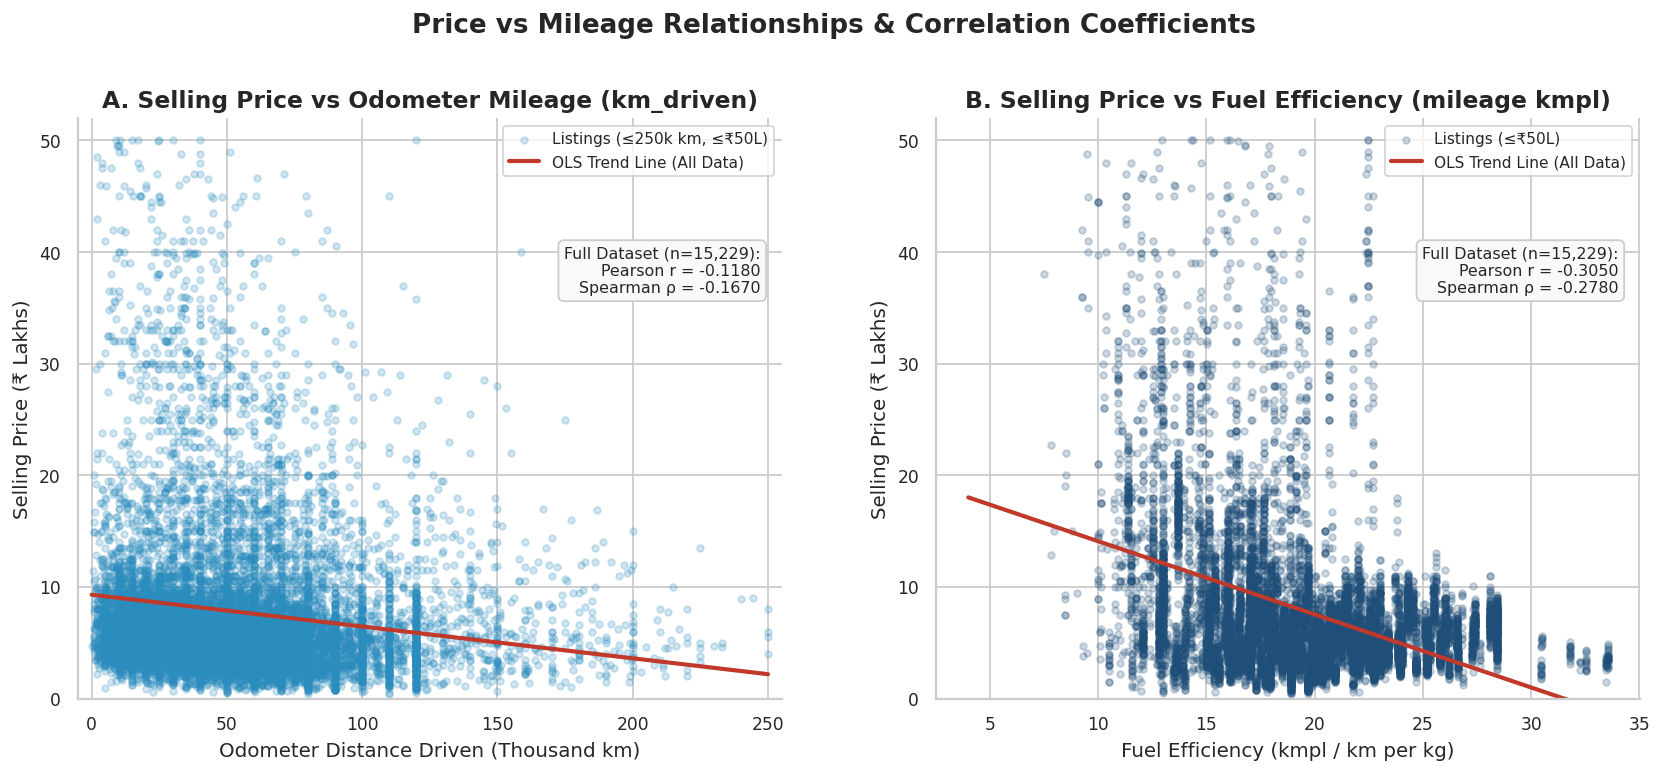

Saved: /home/panha/car_price_prediction/Car_Sale_Analysis/EDA/figures/eda_02_price_vs_mileage_scatter.png


In [3]:
corr_rows = []
for col, label in [
    ("km_driven", "km_driven (Odometer Usage, km)"),
    ("mileage", "mileage (Fuel Efficiency, kmpl)"),
]:
    r_p, p_p = stats.pearsonr(df[col], df["selling_price"])
    r_s, p_s = stats.spearmanr(df[col], df["selling_price"])
    r_lp, p_lp = stats.pearsonr(df[col], df["log_price"])
    corr_rows.append({
        "Variable": label,
        "N": len(df),
        "Pearson_r": r_p,
        "Pearson_p": p_p,
        "Spearman_rho": r_s,
        "Spearman_p": p_s,
        "Pearson_r_logPrice": r_lp,
    })

display(
    pd.DataFrame(corr_rows).style.format({
        "N": "{:,}",
        "Pearson_r": "{:+.4f}",
        "Pearson_p": "{:.2e}",
        "Spearman_rho": "{:+.4f}",
        "Spearman_p": "{:.2e}",
        "Pearson_r_logPrice": "{:+.4f}",
    })
)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))
fig.subplots_adjust(wspace=0.22)

# Left: Selling Price vs Odometer Distance (km_driven)
ax = axes[0]
vis_km = df[(df["km_driven"] <= 250_000) & (df["selling_price"] <= 50 * LAKH)]
ax.scatter(vis_km["km_driven_k"], vis_km["selling_price_lakhs"], s=14, alpha=0.22, color=PALETTE["secondary"], label="Listings (≤250k km, ≤₹50L)")
m_k, b_k = np.polyfit(df["km_driven_k"], df["selling_price_lakhs"], 1)
xg_k = np.linspace(0, 250, 100)
ax.plot(xg_k, m_k * xg_k + b_k, color=PALETTE["danger"], linewidth=2.3, label="OLS Trend Line (All Data)")
r_k_p, _ = stats.pearsonr(df["km_driven"], df["selling_price"])
r_k_s, _ = stats.spearmanr(df["km_driven"], df["selling_price"])
ax.set_xlim(-5, 255)
ax.set_ylim(0, 52)
ax.set_title("A. Selling Price vs Odometer Mileage (km_driven)")
ax.set_xlabel("Odometer Distance Driven (Thousand km)")
ax.set_ylabel("Selling Price (₹ Lakhs)")
ax.legend(loc="upper right", fontsize=8.5, frameon=True)
ax.text(
    0.97, 0.78,
    f"Full Dataset (n={len(df):,}):\nPearson r = {r_k_p:+.4f}\nSpearman ρ = {r_k_s:+.4f}",
    transform=ax.transAxes, ha="right", va="top", fontsize=8.8,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#f8f9fa", edgecolor="#cccccc"),
)

# Right: Selling Price vs Fuel Efficiency (mileage in kmpl)
ax = axes[1]
vis_fe = df[df["selling_price"] <= 50 * LAKH]
ax.scatter(vis_fe["mileage"], vis_fe["selling_price_lakhs"], s=14, alpha=0.22, color=PALETTE["primary"], label="Listings (≤₹50L)")
m_f, b_f = np.polyfit(df["mileage"], df["selling_price_lakhs"], 1)
xg_f = np.linspace(df["mileage"].min(), df["mileage"].max(), 100)
ax.plot(xg_f, m_f * xg_f + b_f, color=PALETTE["danger"], linewidth=2.3, label="OLS Trend Line (All Data)")
r_f_p, _ = stats.pearsonr(df["mileage"], df["selling_price"])
r_f_s, _ = stats.spearmanr(df["mileage"], df["selling_price"])
ax.set_ylim(0, 52)
ax.set_title("B. Selling Price vs Fuel Efficiency (mileage kmpl)")
ax.set_xlabel("Fuel Efficiency (kmpl / km per kg)")
ax.set_ylabel("Selling Price (₹ Lakhs)")
ax.legend(loc="upper right", fontsize=8.5, frameon=True)
ax.text(
    0.97, 0.78,
    f"Full Dataset (n={len(df):,}):\nPearson r = {r_f_p:+.4f}\nSpearman ρ = {r_f_s:+.4f}",
    transform=ax.transAxes, ha="right", va="top", fontsize=8.8,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#f8f9fa", edgecolor="#cccccc"),
)

fig.suptitle("Price vs Mileage Relationships & Correlation Coefficients", fontsize=14.5, fontweight="bold", y=1.02)
out2 = save_eda_figure(fig, "eda_02_price_vs_mileage_scatter.png")
plt.show()
plt.close(fig)
print("Saved:", out2)


**Key Findings (AC 2):**
- **Odometer Mileage (`km_driven`):** Negatively correlated with asking price (`Pearson r = −0.1180`, `Spearman ρ = −0.1670`, `p < 1e-47`). Higher-mileage vehicles generally ask less, though high-priced diesel SUVs/luxury cars weaken the unstratified linear correlation.
- **Fuel Efficiency (`mileage` kmpl):** Negatively correlated with asking price (`Pearson r = −0.3050`, `Spearman ρ = −0.2780`, `p < 1e-260`) because larger, higher-priced engines typically deliver lower fuel efficiency.


## 4. Price vs Vehicle Age Regression Trend Lines

Consistent with `AGENTS.md`, we report results across reliable age cohorts (`n >= 30`, Ages **1–15**, `n = 15,161` = `99.55%`) and exclude the `68` low-sample observations (`Ages 0, 16–29`, including the single Age-25 `BMW 320d` `₹10.00L` anomaly) from trend fitting so sparse tails do not distort the regression slopes.


Reliable Ages 1–15 (n=15,161): Pearson r = -0.2377 | Spearman ρ = -0.4723
Linear OLS slope: ₹-0.73L/yr (R² = 0.0565)
Polynomial Deg 2 R² = 0.0568
Log-Linear slope: -0.1086 (-10.30%/yr, Log R² = 0.2194)


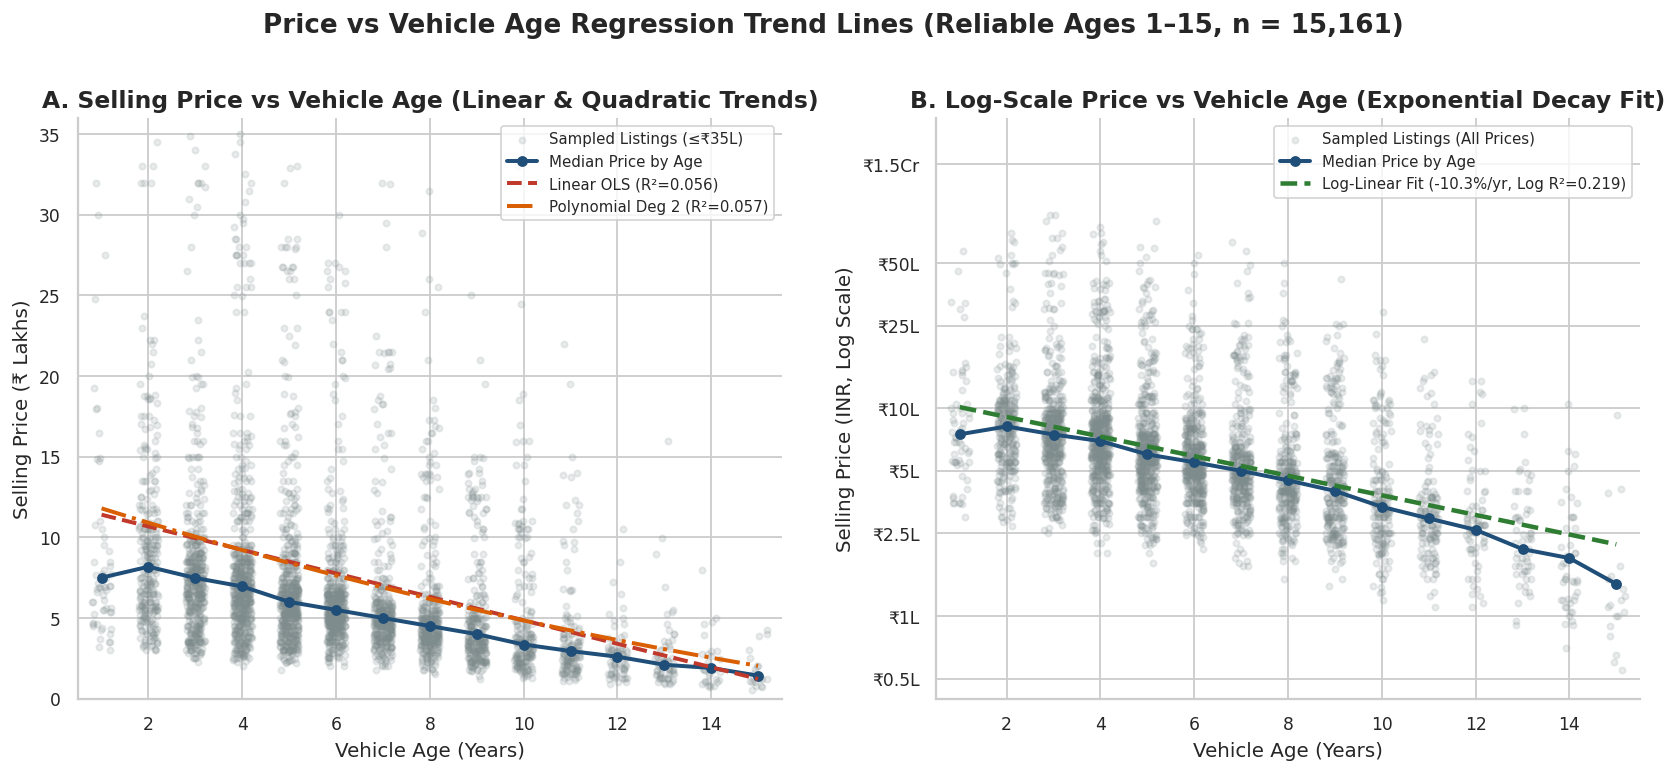

Saved: /home/panha/car_price_prediction/Car_Sale_Analysis/EDA/figures/eda_03_price_vs_vehicle_age_regression.png


In [4]:
rel = df[df["vehicle_age"].between(1, 15)].copy()
age_med = rel.groupby("vehicle_age")["selling_price"].agg(["count", "median", "mean"]).reset_index()

x = rel["vehicle_age"].to_numpy(dtype=float)
y = rel["selling_price"].to_numpy(dtype=float)
log_y = np.log(y)

# Fit Linear OLS, Polynomial Deg 2, and Log-Linear OLS
coef_lin = np.polyfit(x, y, 1)
coef_poly2 = np.polyfit(x, y, 2)
coef_log = np.polyfit(x, log_y, 1)

pred_lin = np.polyval(coef_lin, x)
pred_poly2 = np.polyval(coef_poly2, x)
pred_log_y = np.polyval(coef_log, x)

r2_lin = 1.0 - np.sum((y - pred_lin) ** 2) / np.sum((y - y.mean()) ** 2)
r2_poly2 = 1.0 - np.sum((y - pred_poly2) ** 2) / np.sum((y - y.mean()) ** 2)
r2_log = 1.0 - np.sum((log_y - pred_log_y) ** 2) / np.sum((log_y - log_y.mean()) ** 2)
pct_per_yr = (np.exp(coef_log[0]) - 1.0) * 100.0

r_age_p, p_age_p = stats.pearsonr(x, y)
r_age_s, p_age_s = stats.spearmanr(x, y)
print(f"Reliable Ages 1–15 (n={len(rel):,}): Pearson r = {r_age_p:+.4f} | Spearman ρ = {r_age_s:+.4f}")
print(f"Linear OLS slope: ₹{coef_lin[0]/LAKH:+.2f}L/yr (R² = {r2_lin:.4f})")
print(f"Polynomial Deg 2 R² = {r2_poly2:.4f}")
print(f"Log-Linear slope: {coef_log[0]:+.4f} ({pct_per_yr:+.2f}%/yr, Log R² = {r2_log:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))
fig.subplots_adjust(wspace=0.22)
rng = np.random.default_rng(42)
grid_x = np.linspace(1, 15, 100)

# Left: Raw Price (Lakhs) Scatter + Linear & Polynomial Trend Lines
ax = axes[0]
vis_age = rel[rel["selling_price"] <= 35 * LAKH].sample(4000, random_state=42)
jx = vis_age["vehicle_age"] + rng.uniform(-0.20, 0.20, size=len(vis_age))
ax.scatter(jx, vis_age["selling_price_lakhs"], s=12, alpha=0.16, color=PALETTE["muted"], label="Sampled Listings (≤₹35L)")
ax.plot(age_med["vehicle_age"], age_med["median"] / LAKH, "o-", color=PALETTE["primary"], linewidth=2.2, markersize=5, label="Median Price by Age")
ax.plot(grid_x, np.polyval(coef_lin, grid_x) / LAKH, "--", color=PALETTE["danger"], linewidth=2.2, label=f"Linear OLS (R²={r2_lin:.3f})")
ax.plot(grid_x, np.polyval(coef_poly2, grid_x) / LAKH, "-.", color=PALETTE["accent"], linewidth=2.2, label=f"Polynomial Deg 2 (R²={r2_poly2:.3f})")
ax.set_xlim(0.5, 15.5)
ax.set_ylim(0, 36)
ax.set_title("A. Selling Price vs Vehicle Age (Linear & Quadratic Trends)")
ax.set_xlabel("Vehicle Age (Years)")
ax.set_ylabel("Selling Price (₹ Lakhs)")
ax.legend(loc="upper right", fontsize=8.3, frameon=True)

# Right: Log-Scale Price vs Vehicle Age + Exponential Regression Line
ax = axes[1]
vis_log = rel.sample(4000, random_state=42)
jx2 = vis_log["vehicle_age"] + rng.uniform(-0.20, 0.20, size=len(vis_log))
ax.scatter(jx2, vis_log["selling_price"], s=12, alpha=0.16, color=PALETTE["muted"], label="Sampled Listings (All Prices)")
ax.plot(age_med["vehicle_age"], age_med["median"], "o-", color=PALETTE["primary"], linewidth=2.2, markersize=5, label="Median Price by Age")
ax.plot(grid_x, np.exp(np.polyval(coef_log, grid_x)), "--", color=PALETTE["success"], linewidth=2.5,
        label=f"Log-Linear Fit ({pct_per_yr:+.1f}%/yr, Log R²={r2_log:.3f})")
ax.set_yscale("log")
yticks_age = [50_000, 100_000, 250_000, 500_000, 1_000_000, 2_500_000, 5_000_000, 15_000_000]
ax.set_yticks(yticks_age)
ax.set_yticklabels(["₹0.5L", "₹1L", "₹2.5L", "₹5L", "₹10L", "₹25L", "₹50L", "₹1.5Cr"])
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlim(0.5, 15.5)
ax.set_ylim(40_000, 25_000_000)
ax.set_title("B. Log-Scale Price vs Vehicle Age (Exponential Decay Fit)")
ax.set_xlabel("Vehicle Age (Years)")
ax.set_ylabel("Selling Price (INR, Log Scale)")
ax.legend(loc="upper right", fontsize=8.3, frameon=True)

fig.suptitle("Price vs Vehicle Age Regression Trend Lines (Reliable Ages 1–15, n = 15,161)", fontsize=14.5, fontweight="bold", y=1.02)
out3 = save_eda_figure(fig, "eda_03_price_vs_vehicle_age_regression.png")
plt.show()
plt.close(fig)
print("Saved:", out3)


**Key Findings (AC 3):**
- Vehicle age shows a strong negative rank relationship with asking price (`Spearman ρ = −0.4723`, `p < 1e-300`), rising from `₹7.50L` at Age 1 / `₹8.18L` peak median at Age 2 down to `₹1.43L` by Age 15.
- Because percentage decline compounds across prices spanning budget hatchbacks to luxury cars, the **Log-Linear regression (`Log R² = 0.2194`, `−10.30%/yr`)** models the age trend far better than straight-line OLS (`R² = 0.0565`).


## 5. Model Inventory Frequency & Brand Concentration

We analyze listing counts and market shares across all **`120` models** and **`31` standardized brands** (`ISUZU` merged into `Isuzu`).


Top 5 Models: 26.69% | Top 10 Models: 44.51% | Top 15 Models: 56.34%
Brand Concentration -> Top 1 (Maruti): 32.37% | Top 3: 61.44% | Top 5: 73.15% | Top 10: 91.34%


,model,Brand,Listings,Median_Price,Share_%,Cum_Share_%
0,i20,Hyundai,898,"₹550,000",5.90%,5.90%
1,Swift Dzire,Maruti,875,"₹521,000",5.75%,11.64%
2,Swift,Maruti,774,"₹466,500",5.08%,16.72%
3,Alto,Maruti,768,"₹250,000",5.04%,21.77%
4,City,Honda,750,"₹620,000",4.92%,26.69%
5,Wagon R,Maruti,709,"₹319,000",4.66%,31.35%
6,Grand,Hyundai,569,"₹475,000",3.74%,35.08%
7,Innova,Toyota,542,"₹1,099,500",3.56%,38.64%
8,Verna,Hyundai,488,"₹592,500",3.20%,41.85%
9,i10,Hyundai,406,"₹275,000",2.67%,44.51%


,brand,Listings,Distinct_Models,Median_Price,Share_%,Cum_Share_%
0,Maruti,"4,930",16,"₹465,000",32.37%,32.37%
1,Hyundai,"2,951",10,"₹525,000",19.38%,51.75%
2,Honda,"1,475",7,"₹590,000",9.69%,61.44%
3,Mahindra,998,9,"₹750,000",6.55%,67.99%
4,Toyota,786,5,"₹1,275,000",5.16%,73.15%
5,Ford,775,5,"₹565,000",5.09%,78.24%
6,Volkswagen,613,2,"₹499,000",4.03%,82.26%
7,Renault,525,3,"₹395,000",3.45%,85.71%
8,BMW,436,9,"₹2,287,500",2.86%,88.57%
9,Tata,421,7,"₹550,000",2.76%,91.34%


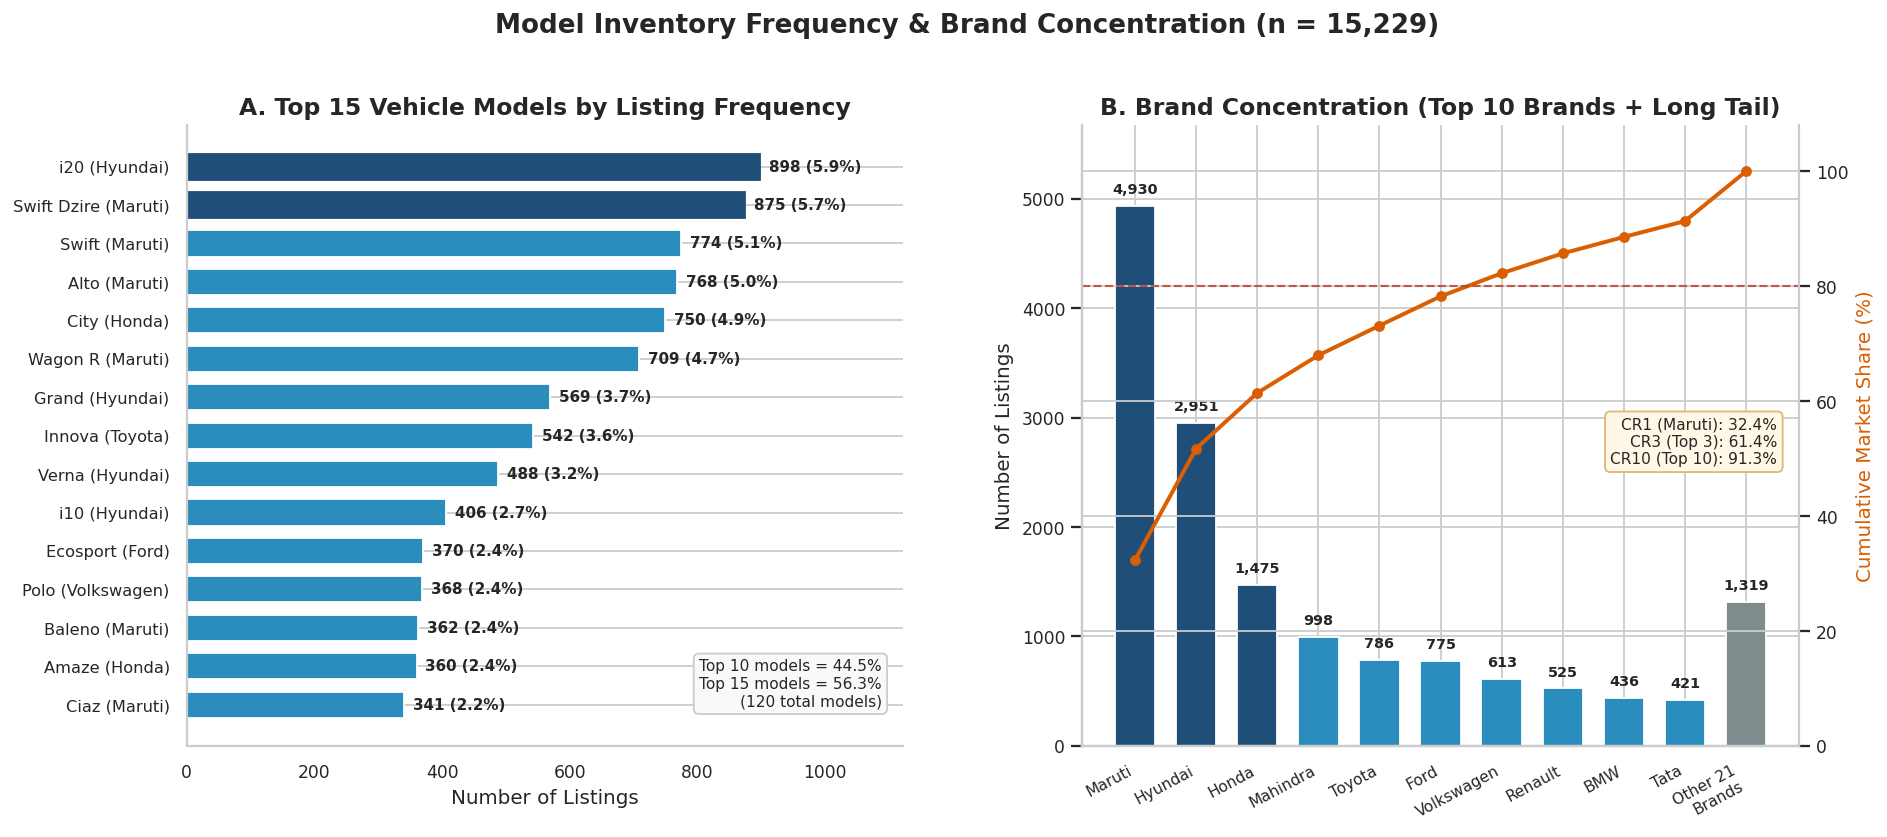

Saved: /home/panha/car_price_prediction/Car_Sale_Analysis/EDA/figures/eda_04_model_frequency_and_brand_concentration.png


In [5]:
model_counts = (
    df.groupby("model")
    .agg(
        Brand=("brand", "first"),
        Listings=("selling_price", "count"),
        Median_Price=("selling_price", "median"),
    )
    .sort_values("Listings", ascending=False)
    .reset_index()
)
model_counts["Share_%"] = model_counts["Listings"] / len(df) * 100.0
model_counts["Cum_Share_%"] = model_counts["Share_%"].cumsum()

brand_counts = (
    df.groupby("brand")
    .agg(
        Listings=("selling_price", "count"),
        Distinct_Models=("model", "nunique"),
        Median_Price=("selling_price", "median"),
    )
    .sort_values("Listings", ascending=False)
    .reset_index()
)
brand_counts["Share_%"] = brand_counts["Listings"] / len(df) * 100.0
brand_counts["Cum_Share_%"] = brand_counts["Share_%"].cumsum()

print(f"Top 5 Models: {model_counts.head(5)['Share_%'].sum():.2f}% | Top 10 Models: {model_counts.head(10)['Share_%'].sum():.2f}% | Top 15 Models: {model_counts.head(15)['Share_%'].sum():.2f}%")
print(f"Brand Concentration -> Top 1 (Maruti): {brand_counts.iloc[0]['Share_%']:.2f}% | Top 3: {brand_counts.head(3)['Share_%'].sum():.2f}% | Top 5: {brand_counts.head(5)['Share_%'].sum():.2f}% | Top 10: {brand_counts.head(10)['Share_%'].sum():.2f}%")

display(
    model_counts.head(15).style.format({
        "Listings": "{:,}",
        "Median_Price": "₹{:,.0f}",
        "Share_%": "{:.2f}%",
        "Cum_Share_%": "{:.2f}%",
    })
)
display(
    brand_counts.head(10).style.format({
        "Listings": "{:,}",
        "Distinct_Models": "{:,}",
        "Median_Price": "₹{:,.0f}",
        "Share_%": "{:.2f}%",
        "Cum_Share_%": "{:.2f}%",
    })
)

fig, axes = plt.subplots(1, 2, figsize=(16.0, 6.2))
fig.subplots_adjust(wspace=0.25)

# Left: Top 15 Vehicle Models by Listing Frequency
ax = axes[0]
top15 = model_counts.head(15).iloc[::-1].reset_index(drop=True)
y_m = np.arange(len(top15))
bars_m = ax.barh(y_m, top15["Listings"], color=PALETTE["secondary"], height=0.68)
bars_m[-1].set_color(PALETTE["primary"])
bars_m[-2].set_color(PALETTE["primary"])
for bar, cnt, sh in zip(bars_m, top15["Listings"], top15["Share_%"]):
    ax.text(cnt + 14, bar.get_y() + bar.get_height() / 2, f"{cnt:,} ({sh:.1f}%)", va="center", fontsize=8.4, fontweight="bold")
ax.set_yticks(y_m)
ax.set_yticklabels([f"{m} ({b})" for m, b in zip(top15["model"], top15["Brand"])], fontsize=9.0)
ax.set_xlim(0, top15["Listings"].max() * 1.25)
ax.set_title("A. Top 15 Vehicle Models by Listing Frequency")
ax.set_xlabel("Number of Listings")
ax.grid(axis="x")
ax.text(
    0.97, 0.06,
    f"Top 10 models = {model_counts.head(10)['Share_%'].sum():.1f}%\nTop 15 models = {model_counts.head(15)['Share_%'].sum():.1f}%\n({len(model_counts)} total models)",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#f8f9fa", edgecolor="#cccccc"),
)

# Right: Brand Concentration Pareto Chart (Top 10 Brands + Other 21 Brands)
ax = axes[1]
top10_b = brand_counts.head(10).copy()
other_cnt = int(brand_counts.iloc[10:]["Listings"].sum())
labels_b = top10_b["brand"].tolist() + [f"Other {len(brand_counts)-10}\nBrands"]
counts_b = top10_b["Listings"].tolist() + [other_cnt]
cum_b = np.cumsum(counts_b) / len(df) * 100.0
x_b = np.arange(len(labels_b))
b_colors = [PALETTE["primary"] if i < 3 else (PALETTE["secondary"] if i < 10 else PALETTE["muted"]) for i in range(len(labels_b))]

bars_b = ax.bar(x_b, counts_b, color=b_colors, width=0.66)
for bar, cnt in zip(bars_b, counts_b):
    ax.text(bar.get_x() + bar.get_width() / 2, cnt + 85, f"{cnt:,}", ha="center", va="bottom", fontsize=8.0, fontweight="bold")
ax.set_xticks(x_b)
ax.set_xticklabels(labels_b, rotation=28, ha="right", fontsize=8.6)
ax.set_ylim(0, max(counts_b) * 1.15)
ax.set_title("B. Brand Concentration (Top 10 Brands + Long Tail)")
ax.set_ylabel("Number of Listings")

ax2 = ax.twinx()
ax2.spines["right"].set_visible(True)
ax2.plot(x_b, cum_b, color=PALETTE["accent"], marker="o", linewidth=2.2, markersize=5, label="Cumulative Share %")
ax2.axhline(80, color=PALETTE["danger"], linestyle="--", linewidth=1.2, alpha=0.8)
ax2.set_ylabel("Cumulative Market Share (%)", color=PALETTE["accent"])
ax2.set_ylim(0, 108)
ax.text(
    0.97, 0.45,
    f"CR1 (Maruti): {brand_counts.iloc[0]['Share_%']:.1f}%\nCR3 (Top 3): {brand_counts.head(3)['Share_%'].sum():.1f}%\nCR10 (Top 10): {brand_counts.head(10)['Share_%'].sum():.1f}%",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#fff8e7", edgecolor="#e0b870"),
)

fig.suptitle("Model Inventory Frequency & Brand Concentration (n = 15,229)", fontsize=14.5, fontweight="bold", y=1.02)
out4 = save_eda_figure(fig, "eda_04_model_frequency_and_brand_concentration.png")
plt.show()
plt.close(fig)
print("Saved:", out4)


**Key Findings (AC 4):**
- **Model Concentration:** Across `120` models, the Top 10 account for **`44.51%`** (`6,779` listings) and Top 15 account for **`56.34%`** (`8,580` listings), led by `i20` (`898`, `5.90%`), `Swift Dzire` (`875`, `5.75%`), `Swift` (`774`, `5.08%`), `Alto` (`768`, `5.04%`), and `City` (`750`, `4.92%`).
- **Brand Concentration:** Across `31` brands, **`Maruti` (`32.37%`) + `Hyundai` (`19.38%`)** supply over half of all listings (`51.75%`). The Top 3 (`+ Honda`) hold **`61.44%`** and the Top 10 hold **`91.34%`**, while the remaining `21` brands make up only `8.66%`.
